# 02 · Exploratory analysis

What drives revenue, and what drives bad reviews? Every chart below is followed by what it means for the business.

Data: the `delivered_orders` view in `olist.db`, which has one row per delivered order purchased Jan 2017 – Aug 2018 (see `sql/schema.md`). Charts are saved to `images/`.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

con = sqlite3.connect("../olist.db")
orders = pd.read_sql_query("SELECT * FROM delivered_orders", con, parse_dates=["purchase_timestamp", "delivered_date", "estimated_date"])
IMAGES = Path("../images")

# One style for every chart: blue = normal, orange = late / problem, grey = context.
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 10, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GREY, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
})

def save(fig, name):
    fig.savefig(IMAGES / f"{name}.png")

brl = mticker.FuncFormatter(lambda x, _: f"R${x/1e6:.1f}M" if x >= 1e6 else f"R${x/1e3:.0f}k")
print(f"{len(orders):,} orders · R${orders.revenue.sum():,.0f} revenue · "
      f"{orders.customer_unique_id.nunique():,} customers")

96,211 orders · R$15,373,120 revenue · 93,104 customers


## 1. Revenue trend

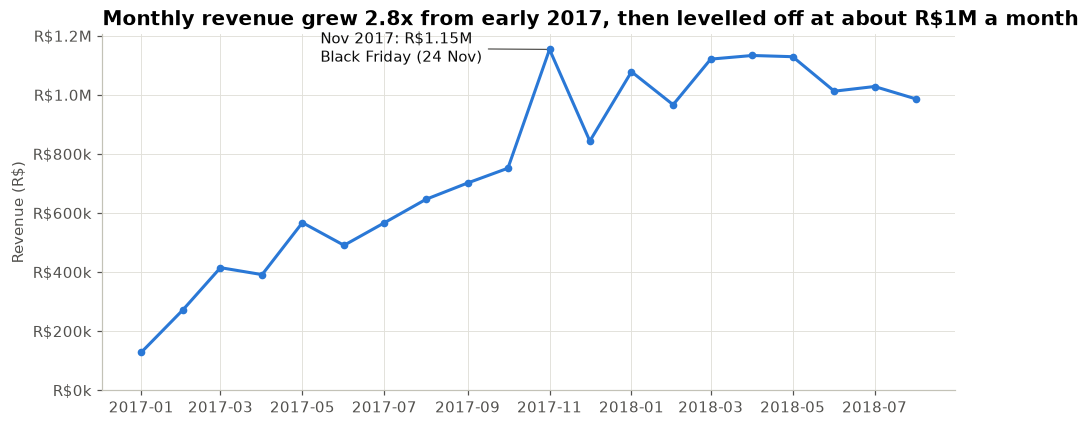

Avg monthly revenue Jan-Jun 2017: R$376,794 · Jan-Aug 2018: R$1,056,448 · ratio 2.8x
Busiest day: 2017-11-24 with 1,147 orders vs median day 148
Nov 2017 vs Oct 2017 revenue: +54%


In [2]:
monthly = (orders.groupby("purchase_month")
           .agg(orders=("order_id", "count"), revenue=("revenue", "sum"))
           .reset_index())
monthly["month"] = pd.to_datetime(monthly.purchase_month)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(monthly.month, monthly.revenue, color=BLUE, lw=2, marker="o", ms=4)
peak = monthly.loc[monthly.revenue.idxmax()]
ax.annotate(f"Nov 2017: R${peak.revenue/1e6:.2f}M\nBlack Friday (24 Nov)", (peak.month, peak.revenue),
            xytext=(-150, -8), textcoords="offset points", color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.yaxis.set_major_formatter(brl)
ax.set_ylim(0)
ax.set_title("Monthly revenue grew 2.8x from early 2017, then levelled off at about R$1M a month")
ax.set_ylabel("Revenue (R$)")
save(fig, "01_monthly_revenue")
plt.show()

h2_2017 = monthly[monthly.purchase_month.between("2017-01", "2017-06")].revenue.mean()
y2018 = monthly[monthly.purchase_month >= "2018-01"].revenue.mean()
daily = orders.groupby("purchase_date").size()
print(f"Avg monthly revenue Jan-Jun 2017: R${h2_2017:,.0f} · Jan-Aug 2018: R${y2018:,.0f} · ratio {y2018/h2_2017:.1f}x")
print(f"Busiest day: {daily.idxmax()} with {daily.max():,} orders vs median day {daily.median():.0f}")
print(f"Nov 2017 vs Oct 2017 revenue: {peak.revenue / monthly.set_index('purchase_month').loc['2017-10','revenue'] - 1:+.0%}")

**What it means:** Olist grew fast through 2017. Average monthly revenue went from R$377k in Jan–Jun 2017 to R$1.06M in 2018 (2.8x), and then stopped growing: every month from March to August 2018 sits between R$0.99M and R$1.13M. The single biggest day was Black Friday, 24 Nov 2017, with 1,147 orders against a median day of 148, which lifted November revenue 54% above October. Growth is now the open question for the business, and Black Friday shows how much demand a promotion can pull in.

## 2. When customers shop

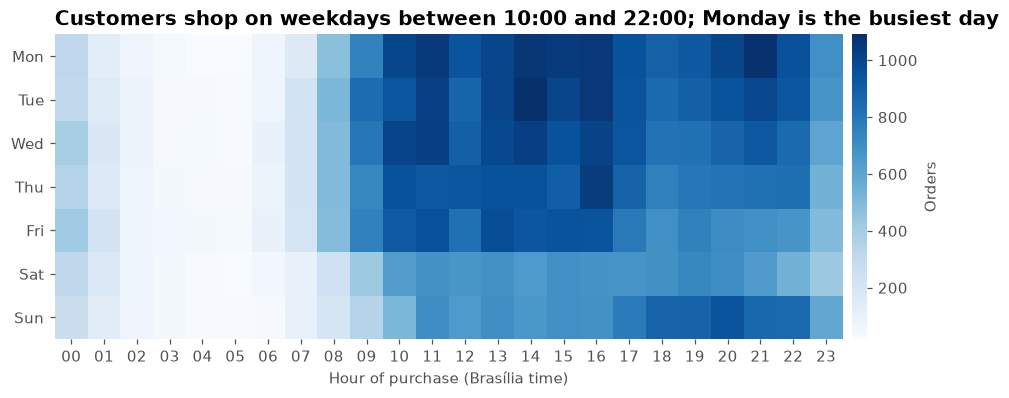

Orders by weekday: {'Mon': 15660, 'Tue': 15449, 'Wed': 15041, 'Thu': 14281, 'Fri': 13646, 'Sat': 10519, 'Sun': 11615}
Share Mon-Fri: 77.0% · share 10:00-21:59: 75.7%
Top 3 hours: {16: 6460, 14: 6368, 11: 6367} · quietest hour: 5


In [3]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
grid = (orders.assign(weekday=orders.purchase_timestamp.dt.day_name().str[:3], hour=orders.purchase_timestamp.dt.hour)
        .pivot_table(index="weekday", columns="hour", values="order_id", aggfunc="count")
        .reindex(days))

fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(grid, cmap="Blues", aspect="auto")
ax.set_xticks(range(24), [f"{h:02d}" for h in range(24)])
ax.set_yticks(range(7), days)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xlabel("Hour of purchase (Brasília time)")
ax.set_title("Customers shop on weekdays between 10:00 and 22:00; Monday is the busiest day")
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("Orders", color=MUTED)
cb.outline.set_visible(False)
save(fig, "02_orders_by_weekday_hour")
plt.show()

by_day = grid.sum(axis=1)
by_hour = grid.sum(axis=0)
print("Orders by weekday:", by_day.to_dict())
print(f"Share Mon-Fri: {by_day[days[:5]].sum()/by_day.sum():.1%} · share 10:00-21:59: {by_hour.loc[10:21].sum()/by_hour.sum():.1%}")
print("Top 3 hours:", by_hour.nlargest(3).to_dict(), "· quietest hour:", by_hour.idxmin())

**What it means:** 77% of orders are placed Monday to Friday, and 76% between 10:00 and 22:00. Monday is the busiest day (15,660 orders) and Saturday the quietest (10,519). People buy during work breaks and in the evening, not overnight. Campaign emails and ads should go out late morning on weekdays, and maintenance windows belong between 02:00 and 06:00.

## 3. Category performance

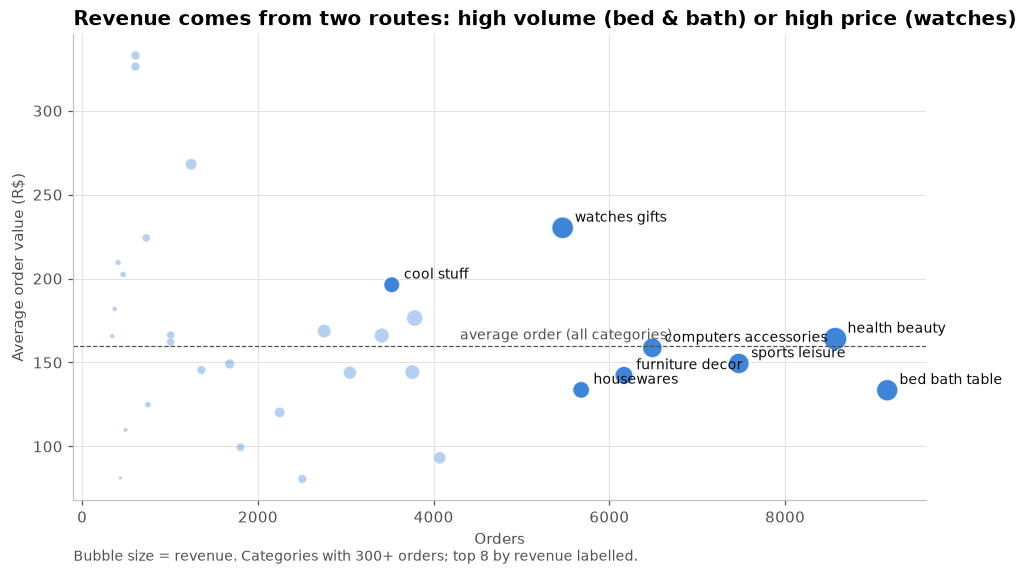

32 categories with 300+ orders; top 8 = 54.4% of all revenue


,orders,revenue,avg_order_value
category,,,
health_beauty,8571,1406568.1,164.1
watches_gifts,5468,1259061.7,230.3
bed_bath_table,9162,1222877.3,133.5
sports_leisure,7474,1116763.4,149.4
computers_accessories,6489,1029873.9,158.7
furniture_decor,6166,877527.5,142.3
housewares,5679,759137.7,133.7
cool_stuff,3523,691665.1,196.3


In [4]:
cats = (orders.groupby("category")
        .agg(orders=("order_id", "count"), revenue=("revenue", "sum"))
        .assign(avg_order_value=lambda d: d.revenue / d.orders))
cats = cats[cats.orders >= 300].sort_values("revenue", ascending=False)
top = cats.head(8)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(cats.orders, cats.avg_order_value, s=cats.revenue / 6e3, color=BLUE, alpha=0.35, edgecolor="white", lw=1)
ax.scatter(top.orders, top.avg_order_value, s=top.revenue / 6e3, color=BLUE, alpha=0.85, edgecolor="white", lw=1)
for name, r in top.iterrows():
    ax.annotate(name.replace("_", " "), (r.orders, r.avg_order_value), xytext=(8, 4),
                textcoords="offset points", fontsize=9, color=INK)
ax.axhline(orders.revenue.mean(), color=MUTED, lw=0.8, ls="--")
ax.text(4300, orders.revenue.mean() + 2, "average order (all categories)", va="bottom", ha="left", color=MUTED, fontsize=9)
ax.set_xlabel("Orders")
ax.set_ylabel("Average order value (R$)")
ax.set_title("Revenue comes from two routes: high volume (bed & bath) or high price (watches)")
ax.text(0, -0.13, "Bubble size = revenue. Categories with 300+ orders; top 8 by revenue labelled.",
        transform=ax.transAxes, color=MUTED, fontsize=9)
save(fig, "03_category_volume_vs_value")
plt.show()

print(f"{len(cats)} categories with 300+ orders; top 8 = {top.revenue.sum()/orders.revenue.sum():.1%} of all revenue")
top.round(1)

**What it means:** The 8 biggest categories bring in 54% of revenue, and they get there in two different ways. Bed, bath & table and health & beauty sell the most orders at an average order value close to or below the R$160 overall average. Watches & gifts sells fewer orders, but each is worth R$230. A volume category needs low shipping costs and fast fulfilment to stay profitable; a high-value category needs trust: reviews, photos and safe delivery.

## 4. Delivery performance

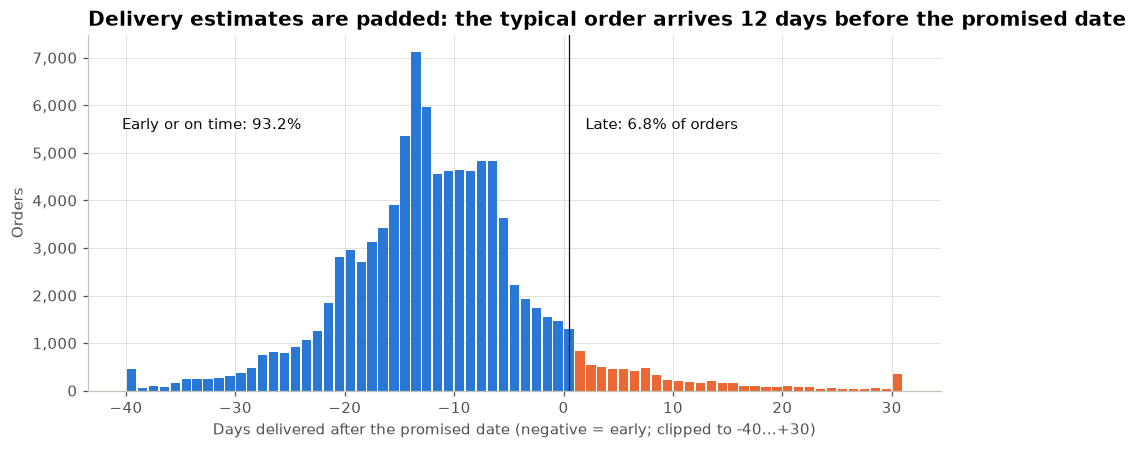

Median days early: 12 · median delivery time: 10.2 days · mean 12.5 · late orders: 6,531.0


In [5]:
d = orders.dropna(subset=["days_late"])
clipped = d.days_late.clip(-40, 30)

fig, ax = plt.subplots(figsize=(10, 4.2))
bins = range(-40, 32)
ax.hist(clipped[clipped <= 0], bins=bins, color=BLUE, rwidth=0.85)
ax.hist(clipped[clipped > 0], bins=bins, color=ORANGE, rwidth=0.85)
ax.axvline(0.5, color=INK, lw=0.8)
ax.text(2, 5500, f"Late: {d.is_late.mean():.1%} of orders", color=INK)
ax.text(-24, 5500, f"Early or on time: {1 - d.is_late.mean():.1%}", color=INK, ha="right")
ax.set_xlabel("Days delivered after the promised date (negative = early; clipped to -40...+30)")
ax.set_ylabel("Orders")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_title("Delivery estimates are padded: the typical order arrives 12 days before the promised date")
save(fig, "04_delivery_vs_estimate")
plt.show()

print(f"Median days early: {-d.days_late.median():.0f} · median delivery time: {d.delivery_days.median():.1f} days · "
      f"mean {d.delivery_days.mean():.1f} · late orders: {d.is_late.sum():,}")

**What it means:** The typical order is delivered 10 days after purchase and 12 days *before* the promised date. Only 6.8% of orders (6,531) arrive late. The estimates are deliberately padded, which is why the late rate looks low. A shorter, honest estimate could win more sales at checkout, but it would push more orders into the 'late' group, which (section 5) is where bad reviews come from.

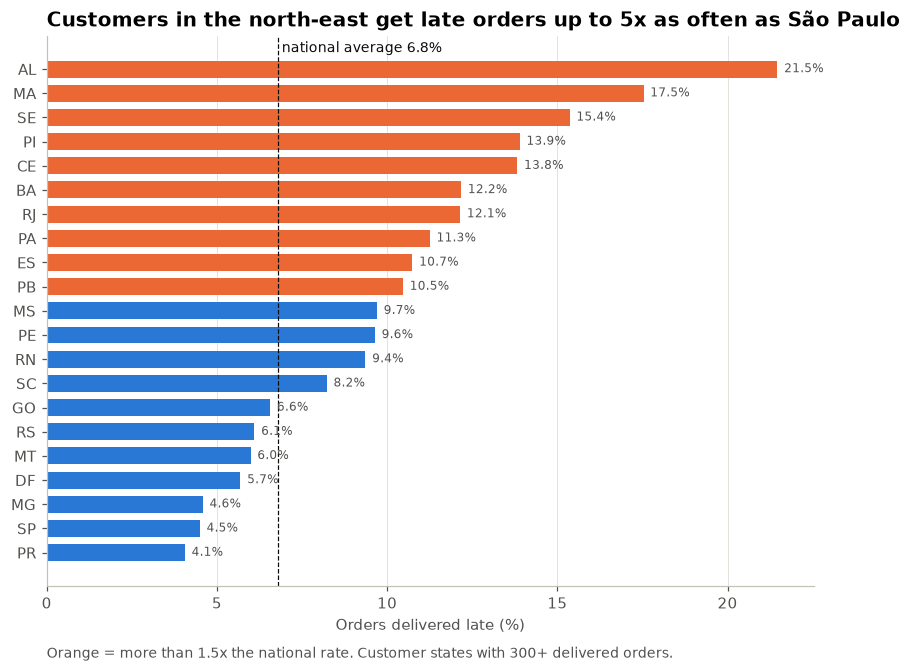

,orders,late_pct,delivery_days
customer_state,,,
AL,396,0.215,24.524
MA,713,0.175,21.537
SE,332,0.154,21.438
PI,475,0.139,19.441
CE,1273,0.138,21.238
BA,3253,0.122,19.334


In [6]:
states = (d.groupby("customer_state")
          .agg(orders=("order_id", "count"), late_pct=("is_late", "mean"), delivery_days=("delivery_days", "mean"))
          .query("orders >= 300")
          .sort_values("late_pct"))
overall = d.is_late.mean()

fig, ax = plt.subplots(figsize=(9, 6.5))
colors = [ORANGE if v > overall * 1.5 else BLUE for v in states.late_pct]
ax.barh(states.index, states.late_pct * 100, color=colors, height=0.7)
ax.axvline(overall * 100, color=INK, lw=0.8, ls="--")
ax.text(overall * 100, len(states) - 0.3, f" national average {overall:.1%}", color=INK, fontsize=9)
for y, (v, n) in enumerate(zip(states.late_pct, states.orders)):
    ax.text(v * 100 + 0.2, y, f"{v:.1%}", va="center", fontsize=8, color=MUTED)
ax.set_xlabel("Orders delivered late (%)")
ax.grid(axis="y", visible=False)
ax.set_title("Customers in the north-east get late orders up to 5x as often as São Paulo")
ax.text(0, -0.13, "Orange = more than 1.5x the national rate. Customer states with 300+ delivered orders.",
        transform=ax.transAxes, color=MUTED, fontsize=9)
save(fig, "05_late_rate_by_state")
plt.show()
states.sort_values("late_pct", ascending=False).head(6).round(3)

**What it means:** Lateness is a geography problem. São Paulo (4.5%) and Paraná (4.1%) almost never get late orders, because most sellers are based there. North-east states like Alagoas (21.5%), Maranhão (17.5%) and Sergipe (15.4%) are late 3–5 times as often, and their orders also take twice as long (19–25 days vs 9–12). Rio de Janeiro is the surprise: a big, close market with a 12.1% late rate. The estimates for distant states need more padding, or those routes need better carriers.

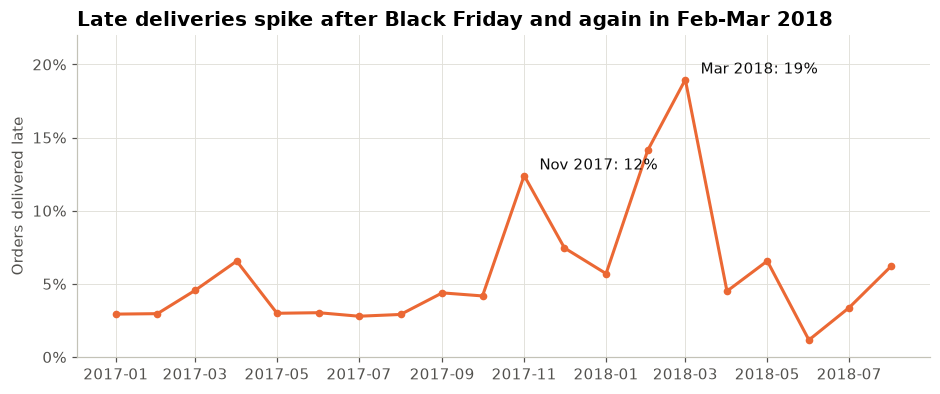

{'2017-01': 0.029,
 '2017-02': 0.03,
 '2017-03': 0.046,
 '2017-04': 0.066,
 '2017-05': 0.03,
 '2017-06': 0.03,
 '2017-07': 0.028,
 '2017-08': 0.029,
 '2017-09': 0.044,
 '2017-10': 0.042,
 '2017-11': 0.124,
 '2017-12': 0.075,
 '2018-01': 0.057,
 '2018-02': 0.141,
 '2018-03': 0.19,
 '2018-04': 0.045,
 '2018-05': 0.066,
 '2018-06': 0.012,
 '2018-07': 0.034,
 '2018-08': 0.062}

In [7]:
late_month = d.groupby("purchase_month").agg(late_pct=("is_late", "mean"), orders=("order_id", "count")).reset_index()
late_month["month"] = pd.to_datetime(late_month.purchase_month)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(late_month.month, late_month.late_pct * 100, color=ORANGE, lw=2, marker="o", ms=4)
for m in ["2017-11", "2018-03"]:
    r = late_month.set_index("purchase_month").loc[m]
    ax.annotate(f"{pd.Timestamp(m):%b %Y}: {r.late_pct:.0%}", (pd.Timestamp(m), r.late_pct * 100),
                xytext=(10, 4), textcoords="offset points", color=INK)
ax.set_ylim(0, 22)
ax.yaxis.set_major_locator(mticker.MultipleLocator(5))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylabel("Orders delivered late")
ax.set_title("Late deliveries spike after Black Friday and again in Feb-Mar 2018")
save(fig, "06_late_rate_by_month")
plt.show()
late_month.set_index("purchase_month").late_pct.round(3).to_dict()

**What it means:** The late rate is normally 3–5%, but it jumped to 12.4% for orders placed in November 2017 (Black Friday) and to 14.1% and 19.0% in February and March 2018. The logistics network could not keep up with demand peaks. Before the next big promotion, carrier capacity and delivery estimates need to be planned for the volume, not set at normal levels.

## 5. What drives bad reviews

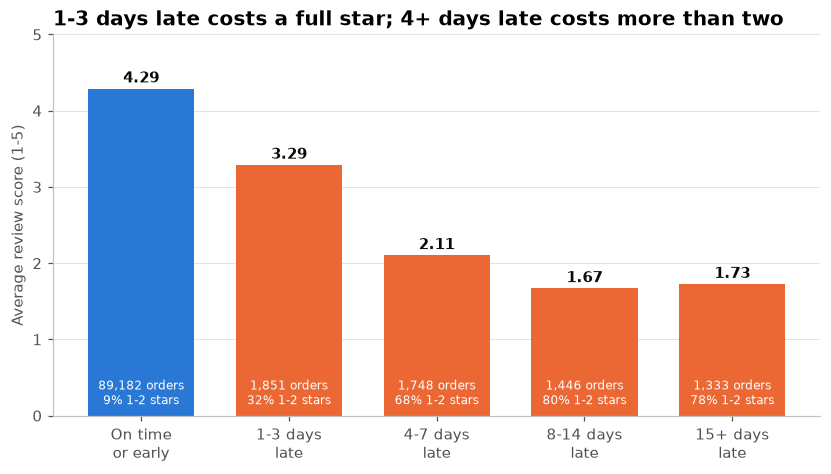

,orders,avg_score,low_pct
bucket,,,
On time\nor early,89182,4.291,0.092
1-3 days\nlate,1851,3.291,0.322
4-7 days\nlate,1748,2.106,0.676
8-14 days\nlate,1446,1.672,0.801
15+ days\nlate,1333,1.727,0.782


In [8]:
bins = [-1000, 0, 3, 7, 14, 1000]
labels = ["On time\nor early", "1-3 days\nlate", "4-7 days\nlate", "8-14 days\nlate", "15+ days\nlate"]
r = d.dropna(subset=["review_score"]).assign(bucket=lambda x: pd.cut(x.days_late, bins=bins, labels=labels))
by_delay = r.groupby("bucket", observed=True).agg(
    orders=("order_id", "count"), avg_score=("review_score", "mean"),
    low_pct=("review_score", lambda s: (s <= 2).mean()))

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(by_delay.index, by_delay.avg_score, color=[BLUE] + [ORANGE] * 4, width=0.72)
for b, (score, n, low) in zip(bars, by_delay[["avg_score", "orders", "low_pct"]].values):
    ax.text(b.get_x() + b.get_width() / 2, score + 0.08, f"{score:.2f}", ha="center", fontweight="bold", color=INK)
    ax.text(b.get_x() + b.get_width() / 2, 0.15, f"{int(n):,} orders\n{low:.0%} 1-2 stars", ha="center", fontsize=8, color="white")
ax.set_ylim(0, 5)
ax.set_ylabel("Average review score (1-5)")
ax.grid(axis="x", visible=False)
ax.set_title("1-3 days late costs a full star; 4+ days late costs more than two")
save(fig, "07_review_score_by_delay")
plt.show()
by_delay.round(3)

**What it means:** This is the headline finding of the project. On-time orders average 4.29 stars, and only 9% get 1 or 2 stars. One to three days late drops the average to 3.29. Four or more days late drops it to around 2 or below, and 68–80% of those customers leave 1 or 2 stars. Late orders are only 6.7% of reviewed orders but cause 32.6% of all 1–2 star reviews. Fixing delivery is the single biggest lever for review scores.

In [9]:
on_time = r[r.is_late == 0]
late = r[r.is_late == 1]
print(f"On-time avg {on_time.review_score.mean():.2f} vs late avg {late.review_score.mean():.2f}")
print(f"Share of all 1-2 star reviews that come from late orders: "
      f"{(late.review_score <= 2).sum() / (r.review_score <= 2).sum():.1%} (late orders are {r.is_late.mean():.1%} of reviewed orders)")

multi = r.assign(split=lambda x: x.sellers.gt(1).map({False: "1 seller", True: "2+ sellers"})).groupby("split").agg(
    orders=("order_id", "count"), avg_score=("review_score", "mean"), late_pct=("is_late", "mean"))
multi.round(3)

On-time avg 4.29 vs late avg 2.27
Share of all 1-2 star reviews that come from late orders: 32.6% (late orders are 6.7% of reviewed orders)


,orders,avg_score,late_pct
split,,,
1 seller,94302,4.174,0.068
2+ sellers,1258,2.855,0.010


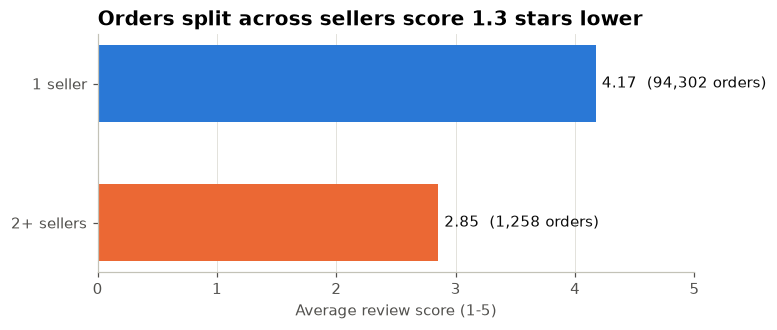

In [10]:
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(multi.index[::-1], multi.avg_score[::-1], color=[ORANGE, BLUE], height=0.55)
for y, (s, n) in enumerate(zip(multi.avg_score[::-1], multi.orders[::-1])):
    ax.text(s + 0.05, y, f"{s:.2f}  ({n:,} orders)", va="center", color=INK)
ax.set_xlim(0, 5)
ax.set_xlabel("Average review score (1-5)")
ax.grid(axis="y", visible=False)
ax.set_title("Orders split across sellers score 1.3 stars lower")
save(fig, "08_review_by_sellers_in_order")
plt.show()

**What it means:** Orders containing items from 2 or more sellers average 2.85 stars against 4.17 for single-seller orders, and 47% of them get 1–2 stars. Lateness does not explain it: only 1.0% of these orders are recorded as late. The likely cause is that items arrive in separate parcels on different days, so the customer reviews an incomplete order. They are only 1.3% of orders, but showing customers that their order will arrive in several parcels, or consolidating shipments, is a cheap fix.

## 6. Customers and geography

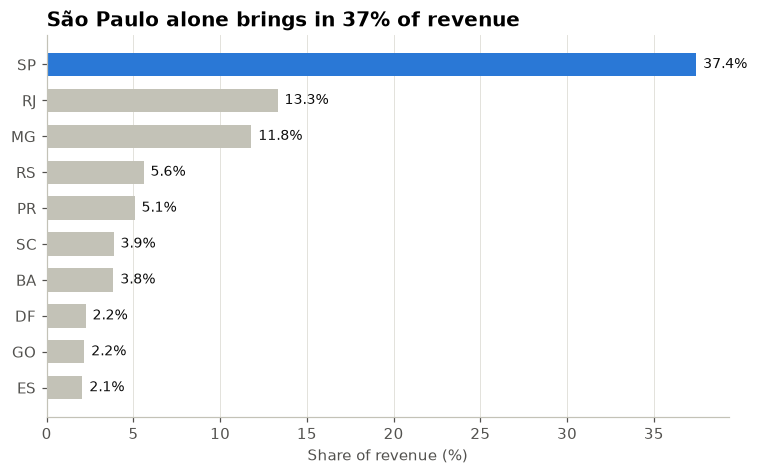

Top 3 states (SP, RJ, MG): 62.6% of revenue · 66.6% of orders
Top cities by revenue: {('sao paulo', 'SP'): 0.137, ('rio de janeiro', 'RJ'): 0.072, ('belo horizonte', 'MG'): 0.026, ('brasilia', 'DF'): 0.022, ('curitiba', 'PR'): 0.015}


In [11]:
geo = orders.groupby("customer_state").agg(orders=("order_id", "count"), revenue=("revenue", "sum")).sort_values("revenue", ascending=False)
geo["share"] = geo.revenue / geo.revenue.sum()
top10 = geo.head(10)[::-1]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top10.index, top10.share * 100, color=[BLUE if s == "SP" else GREY for s in top10.index], height=0.65)
for y, v in enumerate(top10.share):
    ax.text(v * 100 + 0.4, y, f"{v:.1%}", va="center", fontsize=9, color=INK)
ax.set_xlabel("Share of revenue (%)")
ax.grid(axis="y", visible=False)
ax.set_title(f"São Paulo alone brings in {geo.share.iloc[0]:.0%} of revenue")
save(fig, "09_revenue_share_by_state")
plt.show()

cities = orders.groupby(["customer_city", "customer_state"]).revenue.sum().nlargest(5)
print(f"Top 3 states (SP, RJ, MG): {geo.share.head(3).sum():.1%} of revenue · {geo.orders.head(3).sum()/geo.orders.sum():.1%} of orders")
print("Top cities by revenue:", (cities / orders.revenue.sum()).round(3).to_dict())

In [12]:
per_customer = orders.groupby("customer_unique_id").order_id.count()
print(f"{len(per_customer):,} customers · repeat: {(per_customer > 1).mean():.1%} · "
      f"revenue from repeat customers: {orders[orders.customer_unique_id.isin(per_customer[per_customer > 1].index)].revenue.sum() / orders.revenue.sum():.1%}")

93,104 customers · repeat: 3.0% · revenue from repeat customers: 5.6%


**What it means:** Revenue is concentrated: São Paulo state alone brings in 37% and the top three states (SP, RJ, MG) 63%. São Paulo city is 14% of all revenue by itself. Only 3.0% of customers ordered more than once, and they bring in 5.6% of revenue. Olist is almost entirely a first-purchase business, so it keeps paying to acquire every sale. Even a small improvement in repeat rate, for example a post-delivery voucher for customers who received their order on time, would be cheap revenue.

## Summary of findings

1. **Revenue grew 2.8x** from early 2017 to 2018, then levelled off at about R$1M a month. Black Friday 2017 was the biggest day (1,147 orders, 7.7x a normal day).
2. **Late delivery drives bad reviews.** On-time orders average 4.29 stars; 4+ days late averages 2 or below. Late orders are 6.7% of reviewed orders but 32.6% of 1–2 star reviews.
3. **Lateness is regional and seasonal.** North-east states are late 3–5x as often as São Paulo, and the late rate tripled after Black Friday and in Feb–Mar 2018.
4. **Multi-seller orders score 1.3 stars lower** (2.85 vs 4.17) even though they are almost never late, most likely because they arrive in separate parcels.
5. **Customers rarely come back.** Only 3.0% ordered twice, bringing in 5.6% of revenue.
6. **Revenue is concentrated** in São Paulo state (37%) and in 8 categories (54%).

The data-quality checks behind these numbers are in `01_data_quality.ipynb` and `data_quality_report.md`.